# 0. Predicting phases and transition temperatures

## Goal

Run both distributed model families from SMILES: CatBoost on Mordred
descriptors and GATv2Conv on molecular graphs. Compare the reconstructed
phase sequences and save detailed probability and temperature tables.

## Setup

Install `.[notebook,gnn]`. This notebook uses three documented sample
molecules and executes entirely on CPU when no accelerator is available.

### 1. Select and inspect molecules

**Caution.** Confirm that each SMILES string represents the intended neutral compound before interpreting a prediction.

**Extension.** Replace the selected rows with a CSV containing a `SMILES` column.

,ID,SMILES,known
0,1,CCCCCCCCCC(=O)OC1C=C4C(=CC=1)C2C(C3C(CC2)CC(CC...,Cr 76.8 A 112.5 N* 119.8 is
1,2,CCCCCCCCCCC1C=CC(=CC=1)C2C=CC(=CC=2)C(=O)CC(=O)C,Cr 86 E 97 B 107 A 135 is
2,3,CCCCCCCC1C=CC(=CC=1)C2C=CC(=CC=2)C(=O)CCCCC,Cr 94.3 B 95.6 A 103.8 is


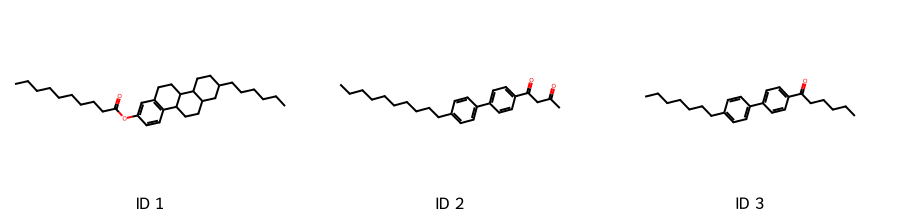

In [1]:
from pathlib import Path

PROJECT_ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
MODEL_DIRECTORY = PROJECT_ROOT / "models"
CATBOOST_PHASE_MODEL = MODEL_DIRECTORY / "CatBoost_phase.cbm"
CATBOOST_TEMPERATURE_MODEL = MODEL_DIRECTORY / "CatBoost_temperature_7000epochs.cbm"
GNN_MODEL = MODEL_DIRECTORY / "GATv2Conv_phase_temp_cv0.pt"
RESULT_DIRECTORY = PROJECT_ROOT / "results"
RESULT_DIRECTORY.mkdir(parents=True, exist_ok=True)

import pandas as pd
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw

sample = pd.DataFrame({
    "ID": [1, 2, 3],
    "SMILES": [
        "CCCCCCCCCC(=O)OC1C=C4C(=CC=1)C2C(C3C(CC2)CC(CCCCCC)CC3)CC4",   # Cr 76.8 A 112.5 N* 119.8 is
        "CCCCCCCCCCC1C=CC(=CC=1)C2C=CC(=CC=2)C(=O)CC(=O)C",             # Cr 86 E 97 B 107 A 135 is
        "CCCCCCCC1C=CC(=CC=1)C2C=CC(=CC=2)C(=O)CCCCC",                  # Cr 94.3 B 95.6 A 103.8 is
    ],
    "known": [
        "Cr 76.8 A 112.5 N* 119.8 is",
        "Cr 86 E 97 B 107 A 135 is",
        "Cr 94.3 B 95.6 A 103.8 is",
    ],
})

display(sample)
Draw.MolsToGridImage(
    [Chem.MolFromSmiles(value) for value in sample["SMILES"]],
    molsPerRow=3,
    subImgSize=(300, 220),
    legends=[f"ID {value}" for value in sample["ID"]],
)

### 2. Predict with CatBoost

**Caution.** A model can only be interpreted with the descriptor definition and target units used during its training.

**Extension.** Set `CATBOOST_PHASE_MODEL` and `CATBOOST_TEMPERATURE_MODEL` above to files from your own training run.

In [2]:
from lc_qspr import CatBoostPredictor

catboost_predictor = CatBoostPredictor(
    CATBOOST_PHASE_MODEL,
    CATBOOST_TEMPERATURE_MODEL,
)
catboost_prediction = catboost_predictor.predict(sample["SMILES"].tolist())
display(catboost_prediction[["SMILES", "predicted_phase_sequence"]])

,SMILES,predicted_phase_sequence
ID,,
0,CCCCCCCCCC(=O)OC1C=C4C(=CC=1)C2C(C3C(CC2)CC(CC...,Cr 75.20 77.73 A 112.53 99.21 N* 116.18 113.79 is
1,CCCCCCCCCCC1C=CC(=CC=1)C2C=CC(=CC=2)C(=O)CC(=O)C,Cr 85.72 85.99 E 97.00 96.89 B 106.93 102.38 A...
2,CCCCCCCC1C=CC(=CC=1)C2C=CC(=CC=2)C(=O)CCCCC,Cr 86.34 92.74 B 94.07 91.83 A 102.33 106.44 is


### 3. Predict with the graph neural network

**Caution.** The distributed checkpoint was trained with no explicit hydrogens and `atom_encoding='none'`; changing either setting is invalid.

**Extension.** Set `GNN_MODEL` above to any compatible checkpoint from your own training run. For an ensemble, load every CV checkpoint and aggregate probabilities and temperatures before applying decision thresholds.

In [3]:
from lc_qspr.gnn import predict_gnn_smiles

gnn_prediction = predict_gnn_smiles(
    sample["SMILES"].tolist(),
    GNN_MODEL,
    atom_encoding="none",
    explicit_hydrogens=False,
)
display(gnn_prediction[["SMILES", "predicted_phase_sequence"]])

,SMILES,predicted_phase_sequence
ID,,
0,CCCCCCCCCC(=O)OC1C=C4C(=CC=1)C2C(C3C(CC2)CC(CC...,Cr 79.96 108.30 is
1,CCCCCCCCCCC1C=CC(=CC=1)C2C=CC(=CC=2)C(=O)CC(=O)C,Cr 98.35 92.18 E 108.23 102.21 A 137.92 137.63 is
2,CCCCCCCC1C=CC(=CC=1)C2C=CC(=CC=2)C(=O)CCCCC,Cr 89.73 88.18 B 98.21 91.78 A 98.93 98.63 is


### 4. Compare model families with known records

**Caution.** These few known records are a usage check, not an independent estimate of generalisation performance.

**Extension.** Use a held-out table with measured phases and temperatures for a formal comparison.


In [4]:
comparison = pd.DataFrame({
    "source_ID": sample["ID"].to_numpy(),
    "CatBoost": catboost_prediction["predicted_phase_sequence"].to_numpy(),
    "GNN": gnn_prediction["predicted_phase_sequence"].to_numpy(),
})

known_key = "known" if "known" in sample.columns else "Phases" if "Phases" in sample.columns else None
if known_key is not None:
    comparison.insert(1, "known", sample[known_key].to_numpy())

display(comparison)

,source_ID,known,CatBoost,GNN
0,1,Cr 76.8 A 112.5 N* 119.8 is,Cr 75.20 77.73 A 112.53 99.21 N* 116.18 113.79 is,Cr 79.96 108.30 is
1,2,Cr 86 E 97 B 107 A 135 is,Cr 85.72 85.99 E 97.00 96.89 B 106.93 102.38 A...,Cr 98.35 92.18 E 108.23 102.21 A 137.92 137.63 is
2,3,Cr 94.3 B 95.6 A 103.8 is,Cr 86.34 92.74 B 94.07 91.83 A 102.33 106.44 is,Cr 89.73 88.18 B 98.21 91.78 A 98.93 98.63 is


### 5. Save full prediction tables

**Caution.** The compact phase string is convenient for reading, but probability and per-transition columns are required for audit and uncertainty review.

**Extension.** Join experimental campaign identifiers before exporting if predictions will move into another research system.

In [5]:
catboost_prediction.insert(0, "source_ID", sample["ID"].to_numpy())
gnn_prediction.insert(0, "source_ID", sample["ID"].to_numpy())
catboost_prediction.to_csv(RESULT_DIRECTORY / "CatBoost_predictions.csv", index=False)
gnn_prediction.to_csv(RESULT_DIRECTORY / "GNN_predictions.csv", index=False)
assert len(catboost_prediction) == len(gnn_prediction) == len(sample)
print("Saved both detailed prediction tables.")

Saved both detailed prediction tables.
